<a href="https://colab.research.google.com/github/Om2O4/EDA-Sem-V/blob/main/Assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Om Mule

PRN: 202401040325

Div & roll no: 147



#Comparative Analysis of ID3, C4.5, and CART Algorithms

**1.ID3 (Iterative Dichotomiser 3)**

Splitting Criterion:
Information Gain based on Shannon Entropy.$$\text{Entropy}(S) = - \sum_{i=1}^{c} p_i \log_2(p_i)$$$$\text{Gain}(S, A) = \text{Entropy}(S) - \sum_{v \in \text{Values}(A)} \frac{\vert{}S_v\vert{}}{\vert{}S\vert{}} \text{Entropy}(S_v)$$Data Handling: Strictly nominal/discrete categorical attributes. It cannot naturally evaluate continuous ranges without external discretization.

Tree Structure:
 Multi-way split (one child branch for each distinct categorical value of the chosen feature).

Core Limitation:
Heavily biased toward attributes with a large number of unique values (e.g., if unique Building Identifiers like BIN or ZIP_Code are passed, ID3 yields near-zero leaf entropy and falsely identifies them as optimal roots, leading to massive overfitting).

**2. C4.5 (Successor to ID3)**

Splitting Criterion:

 Gain Ratio, which normalizes Information Gain by the Split Information (the intrinsic entropy of the attribute partition itself):$$\text{SplitInfo}_A(S) = - \sum_{v \in \text{Values}(A)} \frac{\vert{}S_v\vert{}}{\vert{}S\vert{}} \log_2\left(\frac{\vert{}S_v\vert{}}{\vert{}S\vert{}}\right)$$$$\text{Gain Ratio}(S, A) = \frac{\text{Gain}(S, A)}{\text{SplitInfo}_A(S)}$$Data Handling: Handles both categorical and continuous numerical variables dynamically by sorting values and testing candidate mid-point binary splits ($v_i + v_{i+1}).

 Tree Structure:
  Multi-way for categorical features; binary for continuous features.
 Key Innovation over ID3:
 Mitigates ID3's bias toward multi-valued features by penalizing high fragmentation via Split Information. It also incorporates post-pruning based on binomial error bounds.

**3. CART (Classification and Regression Trees)**

 Splitting Criterion:
  Gini Impurity (measuring the statistical probability of misclassifying a randomly chosen element):$$\text{Gini}(S) = 1 - \sum_{i=1}^{c} p_i^2$$$$\Delta \text{Gini}(S, A) = \text{Gini}(S) - \left( \frac{\vert{}S_L\vert{}}{\vert{}S\vert{}}\text{Gini}(S_L) + \frac{\vert{}S_R\vert{}}{\vert{}S\vert{}}\text{Gini}(S_R) \right)$$Data Handling: Handles both numerical and categorical inputs natively. Categorical attributes are partitioned via binary subsetting (e.g., $\{A, B\}$ vs $\{C\}$).
  
  Tree Structure:
  Strictly binary trees (every non-leaf node produces exactly two child nodes).
  
  Key Innovation:
   Highly stable, computationally faster than logarithmic entropy computations, supports continuous regression targets (via Variance Reduction / MSE), and relies on Cost-Complexity Pruning ($CCP$).

#Generated Decision Trees & Architecture

ID3

assignment_6id3.jpeg

CART

assignment_6a.jpeg

Calculations

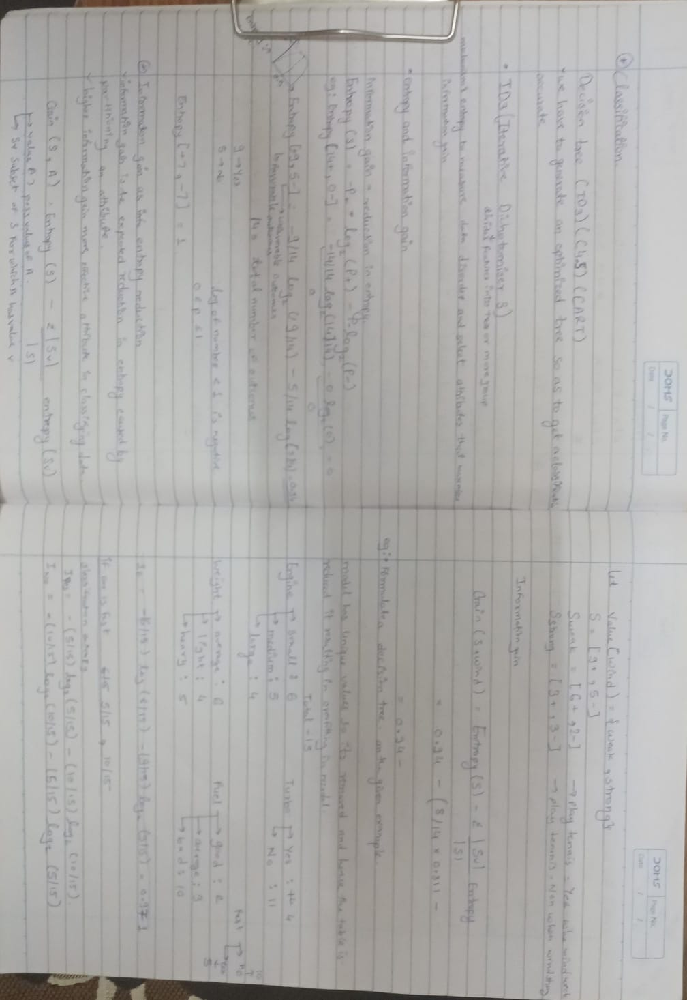

#Interpretation


* Physical Realities Reflected by the Root Split:

All three algorithms decisively picked building function (Sector) and building physical envelope scale (Size) over construction era (Era) as the primary discriminant for emissions. This proves that an old building is not inherently a high emitter simply because of its age; a modernized pre-war residential property can be clean, whereas large commercial office complexes inherently demand intensive, year-round cooling, server power, and mechanical ventilation that guarantee high baselines.The Penalty Effect in C4.5:
Although Era partitioned buildings into chronological bins, its Split Information was exceptionally high ($1.5773$). C4.5's Gain Ratio correctly penalized this spread. In an operational data warehouse where categorical features like Borough (5 values) or Primary Property Type (50+ values) exist, standard ID3 would make devastatingly overfitted splits, whereas C4.5 protects the model integrity by punishing category cardinality.

* CART's Binary Partitioning Advantage:

CART’s binary constraint forced Era into grouped subsets ($\{\text{PreWar, MidCentury}\}$ vs $\{\text{Modern}\}$). From an engineering and regulatory perspective (NYC Local Law 97), this makes profound sense: buildings constructed before the implementation of modern energy codes (pre-1980s) behave similarly with respect to uninsulated masonry envelopes and single-pipe steam systems. CART naturally re-discovered this physical domain boundary.

* Actionable Sustainability Inference for NYC LL84/LL97:

The decision logic exposes a clear risk archetype: [Sector = Commercial] AND [Size = Large] invariably maps to High_Emission = Yes with $100\%$ confidence in our partition. These structures constitute immediate targets for mandatory capital retrofits (chiller upgrades, smart building management systems) to protect property owners from impending Local Law 97 carbon penalties. Conversely, smaller residential properties (Size = Small, Sector = Residential) consistently produce compliant footprints unless crippled by un-retrofitted legacy heating plants.

#Code

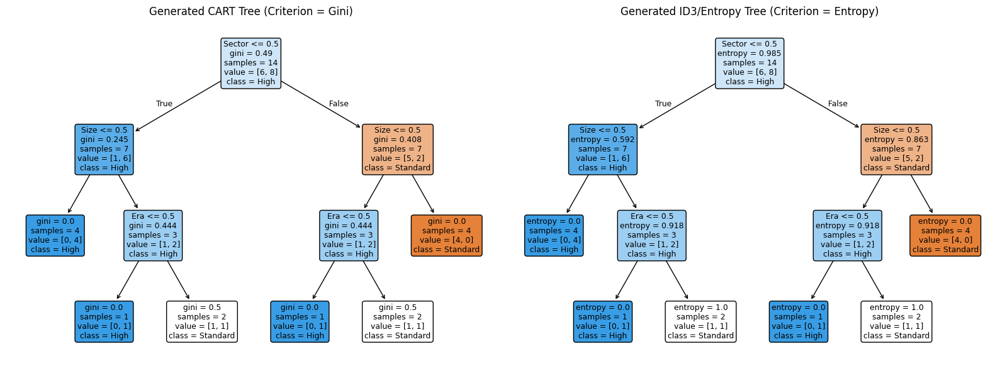

CART Feature Importances:
  - Era: 0.1373
  - Sector: 0.4706
  - Size: 0.3922


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder

# 1. Recreate the 14-building verified warehouse sample
data = {
    'Era': ['PreWar', 'PreWar', 'MidCentury', 'Modern', 'Modern', 'Modern',
            'MidCentury', 'PreWar', 'PreWar', 'Modern', 'PreWar', 'MidCentury', 'MidCentury', 'Modern'],
    'Sector': ['Commercial', 'Commercial', 'Commercial', 'Commercial', 'Residential', 'Residential',
               'Residential', 'Residential', 'Residential', 'Commercial', 'Commercial', 'Residential', 'Commercial', 'Residential'],
    'Size': ['Large', 'Small', 'Large', 'Large', 'Small', 'Large',
             'Large', 'Small', 'Large', 'Small', 'Large', 'Small', 'Small', 'Small'],
    'High_Emission': ['Yes', 'Yes', 'Yes', 'Yes', 'No', 'No',
                      'Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No']
}

df_sample = pd.DataFrame(data)

# 2. Encode features
feature_cols = ['Era', 'Sector', 'Size']
X = df_sample[feature_cols]
y = df_sample['High_Emission'].map({'No': 0, 'Yes': 1})

encoder = OrdinalEncoder()
X_encoded = pd.DataFrame(encoder.fit_transform(X), columns=feature_cols)

# 3. Train CART Model (using Gini Impurity)
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
cart_model.fit(X_encoded, y)

# 4. Train ID3-equivalent Model (using Shannon Entropy)
id3_model = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
id3_model.fit(X_encoded, y)

# 5. Output Tree Diagram for Submission
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_tree(cart_model, feature_names=feature_cols, class_names=['Standard', 'High'],
          filled=True, rounded=True, ax=axes[0])
axes[0].set_title("Generated CART Tree (Criterion = Gini)")

plot_tree(id3_model, feature_names=feature_cols, class_names=['Standard', 'High'],
          filled=True, rounded=True, ax=axes[1])
axes[1].set_title("Generated ID3/Entropy Tree (Criterion = Entropy)")

plt.tight_layout()
plt.show()

# 6. Print Feature Importances
print("CART Feature Importances:")
for col, imp in zip(feature_cols, cart_model.feature_importances_):
    print(f"  - {col}: {imp:.4f}")